# folium: mapas web interactivos

[![Abrir en Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gf0657-programacionsig/2026-ii/blob/main/contenidos/iv-procesamiento-datos-geoespaciales/20-folium-mapas-web.ipynb)

## Trabajo previo

### Lecturas

Antes de la clase, revise las siguientes lecturas, en inglés. La guía de inicio de la documentación oficial recorre, en pocas páginas, lo que hace este cuaderno: crear un mapa, cambiar el mapa base, agregar marcadores y capas vectoriales, y guardar el resultado. La sección del libro de Dorman et al. presenta los mapas interactivos con `explore()`, el método de geopandas que se usó en el cuaderno de geopandas I y que por dentro construye un mapa de folium.

python-visualization. (s. f.). Getting started. En *Folium documentation* (versión 0.20.0). Recuperado el 25 de octubre de 2026, de https://python-visualization.github.io/folium/v0.20.0/getting_started.html
\
\
Dorman, M., Graser, A., Nowosad, J. y Lovelace, R. (2025). Interactive maps. En *Geocomputation with Python* (sección 8.3). CRC Press. https://py.geocompx.org/08-mapping#sec-interactive-maps

### Otros recursos

La [guía del usuario de folium](https://python-visualization.github.io/folium/v0.20.0/user_guide.html) es la referencia de este cuaderno: en particular, las páginas sobre [mapas base](https://python-visualization.github.io/folium/v0.20.0/user_guide/raster_layers/tiles.html), [capas GeoJSON](https://python-visualization.github.io/folium/v0.20.0/user_guide/geojson/geojson.html), [mapas de coropletas](https://python-visualization.github.io/folium/v0.20.0/user_guide/geojson/choropleth.html) y [complementos](https://python-visualization.github.io/folium/v0.20.0/user_guide/plugins.html). La [documentación de Leaflet](https://leafletjs.com/reference.html), la biblioteca de JavaScript que folium usa por debajo, explica el significado de cada opción. La [vista previa de proveedores de teselas](https://leaflet-extras.github.io/leaflet-providers/preview/) muestra los mapas base disponibles y sus condiciones de uso, y la [política de uso de teselas de OpenStreetMap](https://operations.osmfoundation.org/policies/tiles/) dice lo que se puede y no se puede hacer con el mapa base gratuito más usado.

## Introducción

Los mapas de los cuadernos anteriores fueron **estáticos**: imágenes producidas por matplotlib, con una extensión, una escala y una simbología fijadas por quien las hizo. Un **mapa web** es distinto: se muestra en el navegador, y quien lo consulta decide hacia dónde desplazarse, cuánto acercarse y qué capas ver, y obtiene información al pasar el cursor o hacer clic sobre cada entidad. Es la forma en que se publican hoy los mapas en Internet, desde los visores de los institutos geográficos hasta las aplicaciones de transporte, y es el componente geoespacial de la aplicación que se desarrollará en la sección V del curso.

[folium](https://python-visualization.github.io/folium/) es la biblioteca de Python para crear mapas web. Por sí misma no dibuja nada: genera una página HTML con código de [Leaflet](https://leafletjs.com/), la biblioteca de JavaScript de código abierto en que se basan buena parte de los mapas web, y el navegador la ejecuta. La división del trabajo es la del cuaderno de plotly: los datos se preparan en Python (con pandas y geopandas) y la interactividad corre en el navegador. El método `explore()` de geopandas, que se usó en el cuaderno de geopandas I, es un atajo que construye uno de estos mapas; este cuaderno los construye pieza por pieza, lo que permite combinar varias capas, elegir el mapa base, agregar controles y guardar el resultado como una página web que se publica en Internet, por ejemplo en GitHub Pages.

Los datos vuelven a Costa Rica, a la escala en que los mapas web tienen más sentido: la división territorial administrativa del [Instituto Geográfico Nacional](https://www.snitcr.go.cr/) (provincias, 84 cantones y aeródromos, en el SRC oficial CR-SIRGAS / CRTM05, EPSG:8908), la población y la densidad de los cantones según la estimación 2022 del [INEC](https://inec.cr/), ya conocidas de la sección III, un raster de altitud de WorldClim para Centroamérica y los servicios de mapas web del [SNIT](https://www.snitcr.go.cr/). Los archivos están en los directorios [`datos/ign/`](https://github.com/gf0657-programacionsig/2026-ii/tree/main/datos/ign), [`datos/inec/`](https://github.com/gf0657-programacionsig/2026-ii/tree/main/datos/inec) y [`datos/worldclim/`](https://github.com/gf0657-programacionsig/2026-ii/tree/main/datos/worldclim) del repositorio del curso.

Como todos los cuadernos del curso, puede ejecutarse en la nube, con la insignia "Abrir en Google Colab", o localmente, en [Visual Studio Code](https://gf0657-programacionsig.github.io/2026-ii/vscode/) con el ambiente `geopython` como kernel. Colab trae folium y geopandas instalados; mapclassify, que se usa en un mapa con `explore()`, se instala allí con `!pip install mapclassify`. Los mapas de este cuaderno son interactivos también en la versión publicada en el sitio web del curso. El archivo `.ipynb` puede descargarse con el botón de descarga (ícono de flecha hacia abajo) en la parte superior de la página del cuaderno, en el sitio web del curso.

In [1]:
import math
import os

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib
import rasterio
import folium
from folium import plugins
import branca.colormap as cm

# Direcciones de los directorios de datos en el repositorio del curso
DATOS_IGN = "https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/main/datos/ign"
DATOS_INEC = "https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/main/datos/inec"
DATOS_WC = "https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/main/datos/worldclim"

# Colores de los cuadernos anteriores
AZUL = "#1F77B4"
NARANJA = "#D97B1B"

print("folium", folium.__version__)
print("geopandas", gpd.__version__)

folium 0.20.0
geopandas 1.1.4


## Carga de las capas

Las tres capas del IGN se leen como en los cuadernos de geopandas. Vienen en CR-SIRGAS / CRTM05 (EPSG:8908), el SRC oficial de Costa Rica, proyectado y en metros, adecuado para medir; pero los mapas web trabajan con coordenadas geográficas, de modo que la primera operación es reproyectarlas a WGS84 (EPSG:4326). Es la regla de todo el cuaderno: **folium recibe latitudes y longitudes en WGS84**, y una capa en otro SRC no produce un error, sino un mapa vacío (se verá en la clínica):

In [2]:
# Capas del IGN en CRTM05 (EPSG:8908), reproyectadas a WGS84 (EPSG:4326) para el mapa web
provincias = gpd.read_file(f"{DATOS_IGN}/provincias.gpkg").to_crs(4326)
cantones = gpd.read_file(f"{DATOS_IGN}/cantones.gpkg").to_crs(4326)
aerodromos = gpd.read_file(f"{DATOS_IGN}/aerodromos.gpkg").to_crs(4326)

for nombre, capa in [("provincias", provincias), ("cantones", cantones), ("aerodromos", aerodromos)]:
    print(f"{nombre}: {len(capa)} entidades, {capa.geom_type.iloc[0]}, {capa.crs}")

provincias: 7 entidades, MultiPolygon, EPSG:4326
cantones: 84 entidades, MultiPolygon, EPSG:4326
aerodromos: 119 entidades, Point, EPSG:4326


La población y la densidad de los cantones, de la estimación 2022 del INEC, se unen por el código del cantón, como en la sección III. La capa del IGN tiene los 84 cantones actuales y la del INEC sigue la división de 2011, con 82: Monteverde y Puerto Jiménez quedan sin datos, lo que sirve para ver cómo tratan los mapas los valores faltantes:

In [3]:
# Población, área y densidad de los cantones (INEC, 2022), unidas por el código del cantón
poblacion = pd.read_csv(f"{DATOS_INEC}/cantones-2022.csv")
cantones = cantones.merge(poblacion[["codigo_canton", "poblacion", "area_km2", "densidad"]], on="codigo_canton", how="left")

print("Cantones sin datos:", cantones[cantones["poblacion"].isna()]["canton"].tolist())
cantones.drop(columns="geometry").head()

Cantones sin datos: ['Monteverde', 'Puerto Jiménez']


,codigo_provincia,provincia,codigo_canton,canton,poblacion,area_km2,densidad
0,1,San José,101,San José,352381.0,44.62,7897.4
1,1,San José,102,Escazú,71500.0,34.53,2070.7
2,1,San José,103,Desamparados,223226.0,118.89,1877.6
3,1,San José,104,Puriscal,38525.0,555.04,69.4
4,1,San José,105,Tarrazú,17810.0,291.27,61.1


*Ejercicios de esta sección: 1, en la sección de ejercicios al final del cuaderno.*

## Un primer mapa

`folium.Map()` crea el mapa. Sus dos argumentos principales son `location`, el centro inicial como una lista `[latitud, longitud]` (**en ese orden**, al revés que en geopandas y en GeoJSON, donde es (x, y) = (longitud, latitud); es la fuente de error más común con folium), y `zoom_start`, el **nivel de acercamiento** inicial. El objeto se muestra en el cuaderno como cualquier otro, al escribir su nombre al final de la celda; el mapa se puede desplazar con el ratón y acercar con la rueda o los botones:

In [4]:
# Un mapa web centrado en Costa Rica: location es [latitud, longitud]
CENTRO_CR = [9.75, -84.15]

mapa = folium.Map(location=CENTRO_CR, zoom_start=8)
mapa

Lo que el cuaderno muestra es una página web incrustada. El método `render()` del elemento raíz retorna el HTML completo: una página que carga Leaflet desde un servidor de contenido y crea el mapa con unas pocas líneas de JavaScript, con los mismos valores de centro y acercamiento:

In [5]:
# El mapa es una página web: HTML más el JavaScript que crea el mapa de Leaflet
html = mapa.get_root().render()
print(type(mapa))
print(f"{len(html):,} caracteres de HTML")

inicio = html.find("L.map(")
print(html[inicio - 20:inicio + 280])

<class 'folium.folium.Map'>
3,443 caracteres de HTML
102247071f80de6e8 = L.map(
                "map_0a5787e3dc43587102247071f80de6e8",
                {
                    center: [9.75, -84.15],
                    crs: L.CRS.EPSG3857,
                    ...{
  "zoom": 8,
  "zoomControl": true,
  "preferCanvas": false,
}

                }
       


### Teselas y niveles de acercamiento

El fondo del mapa es el **mapa base**, y no es una imagen única sino un mosaico de **teselas** (*tiles*): imágenes cuadradas de 256 píxeles que un servidor tiene precalculadas para cada nivel de acercamiento. En el nivel 0, una sola tesela contiene el mundo entero; en cada nivel siguiente, cada tesela se divide en cuatro, de modo que el nivel $z$ tiene $4^z$ teselas (figura 1). El navegador descarga solo las teselas visibles en pantalla y pide otras al desplazarse o acercarse: así un mapa del mundo con detalle de calles cabe en una página web.

<figure style="text-align: center;">
  <img
    src="https://raw.githubusercontent.com/gf0657-programacionsig/2026-ii/main/contenidos/iv-procesamiento-datos-geoespaciales/img/piramide-teselas.png"
    alt="El mundo en Web Mercator dividido en 1, 4 y 16 teselas en los niveles de acercamiento 0, 1 y 2"
    width="900"
  >
  <figcaption><strong>Figura 1</strong>. La pirámide de teselas de un mapa web: en el nivel 0 una tesela cubre el mundo; en cada nivel siguiente, cada tesela se divide en cuatro. Las teselas se identifican por su nivel y sus índices (x, y), contados desde la esquina superior izquierda. Fuente: elaboración propia con datos de Natural Earth (s. f.).</figcaption>
</figure>

Las teselas están en la proyección [Web Mercator](https://es.wikipedia.org/wiki/Proyecci%C3%B3n_Web_Mercator) (EPSG:3857), que convierte el mundo en un cuadrado: por eso el mapa web muestra una Groenlandia enorme, como se vio en la lección 16, y por eso excluye las latitudes por encima de 85°. Cada tesela se identifica por su nivel $z$ y sus índices $x$ y $y$, y su dirección en el servidor sigue el patrón `{z}/{x}/{y}.png`. Con la fórmula de la proyección se calcula a qué tesela pertenece un punto en cada nivel:

In [6]:
# Índices (x, y) de la tesela que contiene un punto, en un nivel de acercamiento dado
def tesela(latitud, longitud, nivel):
    n = 2 ** nivel
    x = int((longitud + 180) / 360 * n)
    lat = math.radians(latitud)
    y = int((1 - math.log(math.tan(lat) + 1 / math.cos(lat)) / math.pi) / 2 * n)
    return x, y

# El centro de San José en cuatro niveles
for nivel in [0, 5, 10, 15]:
    print(f"Nivel {nivel:2}: tesela {tesela(9.93, -84.08, nivel)} de {4 ** nivel:,}")

Nivel  0: tesela (0, 0) de 1
Nivel  5: tesela (8, 15) de 1,024
Nivel 10: tesela (272, 483) de 1,048,576
Nivel 15: tesela (8730, 15475) de 1,073,741,824


Y se puede pedir esa tesela directamente al servidor de OpenStreetMap, como la imagen PNG que es:

In [7]:
# La tesela del nivel 10 que contiene el centro de San José, tal como la sirve OpenStreetMap
from IPython.display import Image

x, y = tesela(9.93, -84.08, 10)
url = f"https://tile.openstreetmap.org/10/{x}/{y}.png"
print(url)
Image(url=url)

https://tile.openstreetmap.org/10/272/483.png


Un mapa web es, entonces, una pila: las teselas del mapa base abajo, las capas con los datos propios encima, y los controles. Lo que sigue recorre la pila de abajo hacia arriba.

*Ejercicios de esta sección: 10, en la sección de ejercicios al final del cuaderno.*

## Mapas base

El argumento `tiles` de `folium.Map()` elige el mapa base. El predeterminado es `"OpenStreetMap"`, el mapa colaborativo y libre; folium acepta además los nombres del catálogo de [xyzservices](https://xyzservices.readthedocs.io/), que reúne más de 200 proveedores de teselas, como `"OpenTopoMap"` (relieve y curvas de nivel) o `"Esri.WorldImagery"` (imágenes de satélite):

In [8]:
# Mapa base topográfico
mapa = folium.Map(location=CENTRO_CR, zoom_start=8, tiles="OpenTopoMap")
mapa

Varios mapas base pueden convivir en el mismo mapa: cada `folium.TileLayer` se agrega con `add_to()`, y `folium.LayerControl()` añade el **control de capas**, el ícono de la esquina superior derecha que permite elegir el mapa base y mostrar u ocultar las demás capas. `show=False` deja el mapa base en el control sin mostrarlo al inicio (de lo contrario, el último agregado es el visible), y `control_scale=True` agrega la barra de escala. Este patrón, crear el mapa, agregarle elementos con `add_to()` y terminar con el control de capas, es el de todo el cuaderno:

In [9]:
# Varios mapas base con un control para elegirlos y una barra de escala
mapa = folium.Map(location=CENTRO_CR, zoom_start=8, control_scale=True)  # OpenStreetMap por defecto

folium.TileLayer("OpenTopoMap", name="Topográfico (OpenTopoMap)", show=False).add_to(mapa)
folium.TileLayer("Esri.WorldImagery", name="Imágenes de satélite (Esri)", show=False).add_to(mapa)
folium.TileLayer("Esri.WorldGrayCanvas", name="Fondo gris (Esri)", show=False).add_to(mapa)

folium.LayerControl().add_to(mapa)
mapa

Cualquier otro servidor de teselas se agrega con su patrón de dirección y la **atribución** obligatoria (`attr`), el texto de la esquina inferior derecha que reconoce al autor de los datos; folium la rellena sola para los proveedores del catálogo y la exige para los demás. La versión humanitaria de OpenStreetMap, por su dirección:

In [10]:
# Un mapa base por su patrón de dirección, con la atribución obligatoria
mapa = folium.Map(location=CENTRO_CR, zoom_start=8)

folium.TileLayer(
    tiles="https://{s}.tile.openstreetmap.fr/hot/{z}/{x}/{y}.png",
    attr='&copy; <a href="https://www.openstreetmap.org/copyright">OpenStreetMap</a> contributors, '
         'estilo del <a href="https://www.hotosm.org/">Humanitarian OpenStreetMap Team</a>',
    name="OpenStreetMap humanitario"
).add_to(mapa)

folium.LayerControl().add_to(mapa)
mapa

La tabla 1 resume los mapas base de uso libre más útiles. Dos advertencias. Los mapas base de CARTO (`"CartoDB positron"`, `"CartoDB dark_matter"`), muy usados en ejemplos y documentación, exigen desde 2026 una clave de API, y sin ella aparecen con la marca "API KEY REQUIRED": no conviene usarlos. Y OpenStreetMap sirve sus teselas gratis para usos moderados, como un cuaderno, un sitio en GitHub Pages o la aplicación del proyecto final, pero su política de uso prohíbe el uso masivo; una aplicación con muchos usuarios necesita un proveedor propio.

<figure style="text-align: center; margin: 20px 0;">
    <figcaption><strong>Tabla 1</strong>. Mapas base de uso libre en folium, por el nombre con que se piden en <code>tiles</code> o <code>TileLayer</code>. Fuente: elaboración propia con base en xyzservices (s. f.) y en las condiciones de cada proveedor.</figcaption>
    <table class="table table-bordered table-striped" style="margin: 0 auto;">
    <thead>
      <tr><th>Nombre</th><th>Contenido</th><th>Uso típico</th></tr>
    </thead>
    <tbody>
      <tr><td><code>OpenStreetMap</code></td><td>Calles, lugares y topónimos del mapa colaborativo</td><td>Mapa base general; el predeterminado</td></tr>
      <tr><td><code>OpenTopoMap</code></td><td>Relieve sombreado y curvas de nivel sobre OpenStreetMap</td><td>Temas físicos: altitud, cuencas, rutas</td></tr>
      <tr><td><code>Esri.WorldImagery</code></td><td>Mosaico de imágenes de satélite y aéreas</td><td>Cobertura de la tierra, verificación visual</td></tr>
      <tr><td><code>Esri.WorldTopoMap</code></td><td>Mapa topográfico con relieve y topónimos</td><td>Mapas de referencia</td></tr>
      <tr><td><code>Esri.WorldGrayCanvas</code></td><td>Fondo gris claro con pocos rótulos</td><td>Coropletas y capas temáticas que deben destacar</td></tr>
      <tr><td><code>OpenStreetMap.HOT</code></td><td>Estilo humanitario de OpenStreetMap</td><td>Infraestructura y servicios</td></tr>
      <tr><td><code>NASAGIBS.ViirsEarthAtNight2012</code></td><td>Luces nocturnas (NASA)</td><td>Asentamientos y actividad económica</td></tr>
    </tbody>
    </table>
</figure>

*Ejercicios de esta sección: 1, en la sección de ejercicios al final del cuaderno.*

## Marcadores y ventanas emergentes

`folium.Marker()` coloca un **marcador** en una ubicación `[latitud, longitud]`. Su `tooltip` es la **etiqueta emergente** que aparece al pasar el cursor; su `popup`, la **ventana emergente** que se abre al hacer clic, y que admite HTML (negritas, saltos de línea, enlaces, imágenes); y su `icon` cambia el color y el símbolo, con los íconos de [Font Awesome](https://fontawesome.com/icons) si se indica `prefix="fa"`. Tres lugares del centro de San José:

In [11]:
# Marcadores con etiqueta, ventana emergente e ícono
mapa = folium.Map(location=[9.934, -84.075], zoom_start=16)

folium.Marker(
    location=[9.9332, -84.0770],
    tooltip="Teatro Nacional",
    popup=folium.Popup("<b>Teatro Nacional de Costa Rica</b><br>Inaugurado en 1897", max_width=250),
    icon=folium.Icon(color="darkblue", icon="landmark", prefix="fa")
).add_to(mapa)

folium.Marker(
    location=[9.9328, -84.0717],
    tooltip="Museo Nacional",
    popup=folium.Popup('<b>Museo Nacional de Costa Rica</b><br><a href="https://www.museocostarica.go.cr/" target="_blank">Sitio web</a>', max_width=250),
    icon=folium.Icon(color="green", icon="building-columns", prefix="fa")
).add_to(mapa)

folium.Marker(
    location=[9.9347, -84.0820],
    tooltip="Mercado Central",
    icon=folium.Icon(color="orange", icon="basket-shopping", prefix="fa")
).add_to(mapa)

mapa

Para muchos puntos, el marcador con ícono resulta pesado. `folium.CircleMarker()` dibuja un círculo de radio fijo **en píxeles** (no cambia de tamaño al acercarse) y admite `color`, `fill_color` y `fill_opacity`, como los puntos de matplotlib; `folium.Circle()` dibuja un círculo con radio **en metros**, que sí escala con el mapa: la diferencia se ve al acercarse y alejarse. Un marcador de cada tipo alrededor de la Universidad de Costa Rica:

In [12]:
# CircleMarker (radio en píxeles) frente a Circle (radio en metros)
UCR = [9.9364, -84.0508]
mapa = folium.Map(location=UCR, zoom_start=15)

folium.CircleMarker(location=UCR, radius=8, color=NARANJA, fill=True, fill_opacity=0.8, tooltip="CircleMarker: 8 píxeles").add_to(mapa)
folium.Circle(location=UCR, radius=500, color=AZUL, fill=True, fill_opacity=0.1, tooltip="Circle: 500 m").add_to(mapa)

mapa

### Puntos de una capa

Con una capa de puntos, los marcadores se agregan en un ciclo. `itertuples()` recorre las filas del GeoDataFrame; la latitud y la longitud de cada punto son `geometry.y` y `geometry.x` (de nuevo, en ese orden para folium). Un `folium.FeatureGroup` agrupa los marcadores en una capa con nombre, que el control de capas puede mostrar u ocultar en bloque. Los 119 aeródromos del IGN:

In [13]:
# Un marcador circular por aeródromo, en una capa con nombre
mapa = folium.Map(location=CENTRO_CR, zoom_start=8)

capa_aerodromos = folium.FeatureGroup(name="Aeródromos").add_to(mapa)
for aerodromo in aerodromos.itertuples():
    folium.CircleMarker(
        location=[aerodromo.geometry.y, aerodromo.geometry.x],
        radius=4, color=NARANJA, fill=True, fill_opacity=0.8,
        tooltip=aerodromo.nombre
    ).add_to(capa_aerodromos)

folium.LayerControl().add_to(mapa)
mapa

Cuando los puntos son cientos o miles, se **agrupan**: el complemento `MarkerCluster` reúne los marcadores cercanos en un círculo con el número de puntos, que se despliega al acercarse. Los marcadores se agregan al agrupador en lugar del mapa:

In [14]:
# Marcadores agrupados: el agrupador sustituye al mapa como destino de add_to()
mapa = folium.Map(location=CENTRO_CR, zoom_start=8)

agrupador = plugins.MarkerCluster(name="Aeródromos").add_to(mapa)
for aerodromo in aerodromos.itertuples():
    folium.Marker(
        location=[aerodromo.geometry.y, aerodromo.geometry.x],
        popup=aerodromo.nombre,
        icon=folium.Icon(color="gray", icon="plane", prefix="fa")
    ).add_to(agrupador)

folium.LayerControl().add_to(mapa)
mapa

*Ejercicios de esta sección: 2 y 3, en la sección de ejercicios al final del cuaderno.*

## Capas vectoriales

Las líneas y los polígonos, y también los puntos, se agregan con `folium.GeoJson()`, que recibe un GeoDataFrame (o un archivo o una cadena de texto) y lo convierte en [GeoJSON](https://es.wikipedia.org/wiki/GeoJSON), el formato de texto en que los mapas web intercambian geometrías con atributos, siempre en WGS84. Sus argumentos principales: `style_function`, una función que recibe cada entidad (*feature*) y retorna un diccionario con su estilo (`color` y `weight` para el borde, `fillColor` y `fillOpacity` para el relleno, con los nombres de Leaflet); `highlight_function`, el estilo al pasar el cursor; y `tooltip` y `popup`, con `folium.GeoJsonTooltip()` y `folium.GeoJsonPopup()`, que reciben los nombres de las columnas (`fields`) y las etiquetas con que mostrarlas (`aliases`). Las provincias, con un estilo fijo:

In [15]:
# Polígonos con estilo fijo, resaltado al pasar el cursor y etiqueta emergente
mapa = folium.Map(location=CENTRO_CR, zoom_start=8, tiles="Esri.WorldGrayCanvas")

folium.GeoJson(
    provincias,
    name="Provincias",
    style_function=lambda entidad: {"color": AZUL, "weight": 2, "fillColor": AZUL, "fillOpacity": 0.1},
    highlight_function=lambda entidad: {"weight": 4, "fillOpacity": 0.3},
    tooltip=folium.GeoJsonTooltip(fields=["provincia"], aliases=["Provincia"])
).add_to(mapa)

folium.LayerControl().add_to(mapa)
mapa

La función de estilo recibe la entidad como un diccionario GeoJSON, y sus atributos están en `entidad["properties"]`: con ellos se asigna un estilo distinto a cada polígono. Un color por provincia, con los siete primeros colores de la paleta categórica de matplotlib, y la ventana emergente con varios atributos:

In [16]:
# Estilo por entidad: un color por provincia, leído de los atributos de cada polígono
COLORES_PROVINCIA = dict(zip(sorted(provincias["provincia"]),
                             ["#1F77B4", "#D97B1B", "#2CA02C", "#D62728", "#9467BD", "#8C564B", "#17BECF"]))

mapa = folium.Map(location=CENTRO_CR, zoom_start=8, tiles="Esri.WorldGrayCanvas")

folium.GeoJson(
    cantones,
    name="Cantones",
    style_function=lambda entidad: {
        "fillColor": COLORES_PROVINCIA[entidad["properties"]["provincia"]],
        "color": "white", "weight": 0.7, "fillOpacity": 0.6
    },
    highlight_function=lambda entidad: {"weight": 3, "color": "#333333"},
    tooltip=folium.GeoJsonTooltip(fields=["canton", "provincia"], aliases=["Cantón", "Provincia"]),
    popup=folium.GeoJsonPopup(fields=["canton", "poblacion", "area_km2", "densidad"],
                              aliases=["Cantón", "Población (2022)", "Área (km²)", "Densidad (hab/km²)"],
                              localize=True)
).add_to(mapa)

folium.LayerControl().add_to(mapa)
mapa

`localize=True` formatea los números según la configuración del navegador (separadores de miles). Monteverde y Puerto Jiménez muestran `NaN` en la ventana emergente: los valores faltantes viajan al GeoJSON tal cual, y si se quiere otro texto hay que sustituirlos antes, con `fillna()`.

`GeoJson()` sirve también para los puntos, sin ciclo: el argumento `marker` recibe el marcador modelo (un `CircleMarker` o un `Marker`) que se repite para cada punto, con la etiqueta emergente tomada de los atributos. Es la forma más corta de agregar una capa de puntos, y la que usa `explore()` por dentro:

In [17]:
# Capa de puntos sin ciclo: un marcador modelo que se repite para cada entidad
mapa = folium.Map(location=CENTRO_CR, zoom_start=8)

folium.GeoJson(
    aerodromos,
    name="Aeródromos",
    marker=folium.CircleMarker(radius=4, color=NARANJA, fill=True, fill_opacity=0.8),
    tooltip=folium.GeoJsonTooltip(fields=["nombre"], aliases=["Aeródromo"])
).add_to(mapa)

folium.LayerControl().add_to(mapa)
mapa

*Ejercicios de esta sección: 4, en la sección de ejercicios al final del cuaderno.*

## Mapas de coropletas

`folium.Choropleth()` construye un mapa de coropletas a partir de dos ingredientes: `geo_data`, las geometrías, y `data`, una tabla con los valores, unidos por una llave que se indica dos veces, en `columns` (la columna llave y la columna de valores de la tabla) y en `key_on` (la ruta al atributo en el GeoJSON, `feature.properties.<columna>`). Las geometrías y la tabla pueden ser el mismo GeoDataFrame, como aquí. `fill_color` es una paleta de ColorBrewer, `bins` los límites de las clases (un número de clases de igual intervalo o una lista de límites), `nan_fill_color` el color de las entidades sin datos y `legend_name` el título de la leyenda, que folium agrega sola.

La densidad de población de los cantones va de 15 a más de 9 000 habitantes por km², con la mayoría por debajo de 200: con intervalos iguales, casi todos los cantones caerían en la primera clase. Los límites se calculan por **cuantiles**, con pandas, y se completan con 0 y el máximo redondeado hacia arriba, porque `Choropleth` exige que todos los valores caigan dentro de los límites:

In [18]:
# Límites de clase por quintiles de la densidad, completados con 0 y el máximo
cuantiles = cantones["densidad"].quantile([0.2, 0.4, 0.6, 0.8]).round().tolist()
limites = [0] + cuantiles + [math.ceil(cantones["densidad"].max())]
print("Límites de las clases:", limites)

Límites de las clases: [0, 42.0, 66.0, 186.0, 927.0, 9020]


In [19]:
# Mapa de coropletas de la densidad de población por cantón
mapa = folium.Map(location=CENTRO_CR, zoom_start=8, tiles="Esri.WorldGrayCanvas")

coropletas = folium.Choropleth(
    geo_data=cantones,
    data=cantones,
    columns=["codigo_canton", "densidad"],
    key_on="feature.properties.codigo_canton",
    bins=limites,
    fill_color="YlOrRd",
    fill_opacity=0.8,
    line_color="white",
    line_weight=0.7,
    nan_fill_color="#E6E6E6",
    legend_name="Densidad de población, 2022 (hab/km²)",
    highlight=True,
    name="Densidad de población"
).add_to(mapa)

folium.LayerControl().add_to(mapa)
mapa

`Choropleth` no tiene argumento `tooltip`, pero su atributo `geojson` es la capa `GeoJson` que dibuja los polígonos, y a ella se le agrega una etiqueta emergente con `add_child()`. Los dos cantones nuevos quedan en gris, y la leyenda muestra los cortes por quintiles:

In [20]:
# Etiqueta emergente sobre la capa GeoJson interna del mapa de coropletas
coropletas.geojson.add_child(
    folium.GeoJsonTooltip(fields=["canton", "poblacion", "densidad"],
                          aliases=["Cantón", "Población", "Densidad (hab/km²)"],
                          localize=True)
)

mapa

### Una escala propia con branca

`Choropleth` es cómodo, pero su leyenda es fija y su clasificación, limitada. La alternativa general es construir la escala de colores con [branca](https://python-visualization.github.io/branca/), la biblioteca en que folium se apoya para leyendas y colores, y usarla en la función de estilo de un `GeoJson`: `StepColormap` crea una escala por clases con los límites que se le den, se llama como una función que convierte un valor en un color, y `caption` y `add_to()` la agregan como leyenda. Es el patrón que `explore()` y `Choropleth` ejecutan por dentro, y el que permite cualquier regla: aquí, gris para los valores faltantes:

In [21]:
# Escala por clases de branca, usada en la función de estilo de un GeoJson
escala = cm.StepColormap(["#FFFFB2", "#FED976", "#FD8D3C", "#E31A1C", "#800026"],
                         index=limites, vmin=limites[0], vmax=limites[-1],
                         caption="Densidad de población, 2022 (hab/km²)")

def estilo_densidad(entidad):
    densidad = entidad["properties"]["densidad"]
    color = "#E6E6E6" if densidad is None or np.isnan(densidad) else escala(densidad)
    return {"fillColor": color, "color": "white", "weight": 0.7, "fillOpacity": 0.8}

mapa = folium.Map(location=CENTRO_CR, zoom_start=8, tiles="Esri.WorldGrayCanvas")
folium.GeoJson(cantones, name="Densidad de población", style_function=estilo_densidad,
               tooltip=folium.GeoJsonTooltip(fields=["canton", "densidad"], aliases=["Cantón", "Densidad (hab/km²)"], localize=True)).add_to(mapa)
escala.add_to(mapa)
folium.LayerControl().add_to(mapa)
mapa

### explore() y folium, juntos

`explore()`, de geopandas, hace en una línea lo mismo que las celdas anteriores, con mapclassify para clasificar. Y como retorna un `folium.Map`, lo que este cuaderno agrega con `add_to()` (mapas base, capas, complementos) se le puede agregar también. Las dos herramientas no compiten: `explore()` para empezar y folium para completar:

In [22]:
# explore() produce un folium.Map, al que se agregan capas y controles como a cualquier otro
mapa = cantones.explore(
    column="densidad", scheme="Quantiles", k=5, cmap="YlOrRd",
    tooltip=["canton", "densidad"], tiles="Esri.WorldGrayCanvas",
    style_kwds={"color": "white", "weight": 0.7}, missing_kwds={"color": "#E6E6E6"},
    legend_kwds={"caption": "Densidad de población, 2022 (hab/km²)"},
    name="Densidad de población", location=CENTRO_CR, zoom_start=8
)

folium.GeoJson(aerodromos, name="Aeródromos",
               marker=folium.CircleMarker(radius=3, color=AZUL, fill=True, fill_opacity=0.8),
               tooltip=folium.GeoJsonTooltip(fields=["nombre"], aliases=["Aeródromo"])).add_to(mapa)
folium.LayerControl().add_to(mapa)
mapa

*Ejercicios de esta sección: 5 y 6, en la sección de ejercicios al final del cuaderno.*

## Capas raster

Un raster se agrega a un mapa web de dos maneras. La primera es `ImageOverlay`: una imagen colocada entre dos esquinas, `[[sur, oeste], [norte, este]]`. Sirve para un raster pequeño y se construye con lo que se aprendió en el cuaderno de rasterio: se lee la matriz con máscara, se le aplica una paleta de matplotlib (que retorna una imagen RGBA, con el cuarto canal de transparencia) y se hacen transparentes las celdas sin dato. Como el raster está en WGS84 y el mapa en Web Mercator, `mercator_project=True` reproyecta la imagen; sin él, la capa queda estirada respecto del mapa base. La altitud de Centroamérica de WorldClim, con una escala de colores de branca como leyenda:


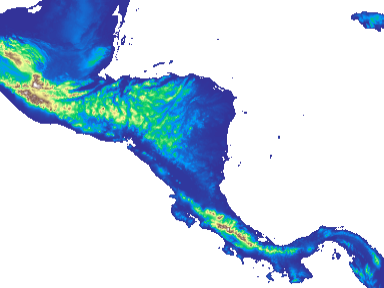

In [23]:
# Raster como imagen superpuesta: matriz con máscara, paleta de matplotlib y transparencia
with rasterio.open(f"{DATOS_WC}/altitud-centroamerica.tif") as altitud:
    matriz = altitud.read(1, masked=True)
    limites_raster = altitud.bounds

paleta = matplotlib.colormaps["terrain"]
imagen = paleta(np.clip(matriz.filled(0), 0, 3500) / 3500)   # RGBA, valores entre 0 y 1
imagen[..., 3] = np.where(matriz.mask, 0, 0.7)                # transparencia: océano invisible, tierra al 70 %

mapa = folium.Map(location=CENTRO_CR, zoom_start=7)
folium.raster_layers.ImageOverlay(
    image=imagen,
    bounds=[[limites_raster.bottom, limites_raster.left], [limites_raster.top, limites_raster.right]],
    mercator_project=True,
    name="Altitud (WorldClim)"
).add_to(mapa)

escala_altitud = cm.LinearColormap([matplotlib.colors.to_hex(paleta(v)) for v in np.linspace(0, 1, 8)],
                                   vmin=0, vmax=3500, caption="Altitud (m)")
escala_altitud.add_to(mapa)
folium.LayerControl().add_to(mapa)
mapa

### Servicios de mapas web

La segunda manera no incrusta la imagen: la pide a un servidor cada vez que el mapa se mueve. Un [servicio de mapas web](https://es.wikipedia.org/wiki/Web_Map_Service) (WMS) es un estándar del [Open Geospatial Consortium](https://www.ogc.org/) por el que un servidor dibuja, a petición, la imagen de una capa para la extensión y el tamaño en píxeles que el cliente le indica. Es lo que ofrecen las instituciones para publicar sus datos sin entregarlos: en Costa Rica, el SNIT del IGN sirve por WMS la cartografía oficial a escalas 1:5 000, 1:25 000 y 1:200 000. `folium.WmsTileLayer()` recibe la dirección del servicio, el nombre de la capa (`layers`) y el formato, con `transparent=True` para que se vea el mapa base debajo. La red de drenaje y la red vial a 1:200 000 sobre San José:

In [24]:
# Capas del servicio WMS del IGN (SNIT) a escala 1:200 000
WMS_IGN_200 = "https://geos.snitcr.go.cr/be/IGN_200/wms?"

mapa = folium.Map(location=[9.93, -84.08], zoom_start=12, tiles="Esri.WorldGrayCanvas")

folium.WmsTileLayer(url=WMS_IGN_200, layers="reddrenaje_200k", fmt="image/png", transparent=True,
                    name="Red de drenaje 1:200 000 (IGN)", attr="Instituto Geográfico Nacional, SNIT").add_to(mapa)
folium.WmsTileLayer(url=WMS_IGN_200, layers="redvial_200k", fmt="image/png", transparent=True,
                    name="Red vial 1:200 000 (IGN)", attr="Instituto Geográfico Nacional, SNIT").add_to(mapa)

folium.LayerControl().add_to(mapa)
mapa

Los nombres de las capas se consultan en la operación `GetCapabilities` del servicio, un documento XML que lista las capas, sus títulos y sus SRC; la dirección es la del servicio seguida de `service=WMS&request=GetCapabilities`. Las capas del IGN están publicadas en CR05 / CRTM05 (EPSG:5367) y en WGS84, y el servidor las reproyecta a Web Mercator cuando Leaflet se las pide así. Muchas capas tienen una **escala mínima** fijada por el servidor y solo se dibujan a partir de cierto acercamiento (la red de drenaje y las curvas de nivel a 1:200 000, desde el nivel 12): por debajo, el servidor responde con teselas vacías, sin ningún error, y la capa parece no existir. El mismo mecanismo funciona con cualquier WMS: el del SINAC para las áreas protegidas, los de los ministerios, los de la NASA o la ESA.

*Ejercicios de esta sección: 7 y 8, en la sección de ejercicios al final del cuaderno.*

## Complementos

Los **complementos** (`folium.plugins`) envuelven extensiones de Leaflet: controles e interacciones que el mapa básico no trae. Ya se usó `MarkerCluster`; los más útiles para un mapa de referencia son el minimapa, el botón de pantalla completa, la herramienta de medición, la posición del cursor y el buscador de lugares, que consulta el geocodificador [Nominatim](https://nominatim.org/) de OpenStreetMap. Todos se agregan con `add_to()`:

In [25]:
# Controles adicionales: minimapa, pantalla completa, medición, posición del cursor y buscador
mapa = folium.Map(location=CENTRO_CR, zoom_start=8, control_scale=True)
folium.TileLayer("Esri.WorldImagery", name="Imágenes de satélite (Esri)").add_to(mapa)

folium.GeoJson(cantones, name="Cantones",
               style_function=lambda entidad: {"color": NARANJA, "weight": 1, "fillOpacity": 0},
               tooltip=folium.GeoJsonTooltip(fields=["canton"], aliases=["Cantón"])).add_to(mapa)

plugins.MiniMap(toggle_display=True, position="bottomleft").add_to(mapa)
plugins.Fullscreen().add_to(mapa)
plugins.MeasureControl(primary_length_unit="kilometers", primary_area_unit="sqkilometers").add_to(mapa)
plugins.MousePosition(position="bottomright", separator=" | ", num_digits=4, prefix="Lat | Lon:").add_to(mapa)
plugins.Geocoder(collapsed=True, add_marker=True).add_to(mapa)

folium.LayerControl().add_to(mapa)
mapa

Otro complemento frecuente es el [mapa de calor](https://es.wikipedia.org/wiki/Mapa_de_calor), `HeatMap`, que recibe una lista de pares `[latitud, longitud]` (y, opcionalmente, un peso) y dibuja la densidad de puntos con un degradado; `radius` controla cuánto se extiende cada punto. Es una alternativa al agrupamiento para ver dónde se concentran los puntos, aunque su lectura depende del acercamiento. Los aeródromos:

In [26]:
# Mapa de calor de los aeródromos: lista de [latitud, longitud]
mapa = folium.Map(location=CENTRO_CR, zoom_start=8, tiles="Esri.WorldGrayCanvas")

coordenadas = [[punto.y, punto.x] for punto in aerodromos.geometry]
plugins.HeatMap(coordenadas, radius=20, blur=15, name="Densidad de aeródromos").add_to(mapa)

folium.LayerControl().add_to(mapa)
mapa

La tabla 2 resume los complementos vistos y otros que conviene conocer.

<figure style="text-align: center; margin: 20px 0;">
    <figcaption><strong>Tabla 2</strong>. Complementos de <code>folium.plugins</code> más usados. Fuente: elaboración propia con base en python-visualization (s. f.-b).</figcaption>
    <table class="table table-bordered table-striped" style="margin: 0 auto;">
    <thead>
      <tr><th>Complemento</th><th>Qué agrega</th><th>Argumento principal</th></tr>
    </thead>
    <tbody>
      <tr><td><code>MarkerCluster</code></td><td>Agrupa los marcadores cercanos según el acercamiento</td><td>Los marcadores se agregan al agrupador</td></tr>
      <tr><td><code>HeatMap</code></td><td>Mapa de calor de una lista de puntos</td><td><code>radius</code>, <code>blur</code>, pesos opcionales</td></tr>
      <tr><td><code>MiniMap</code></td><td>Mapa de ubicación en una esquina</td><td><code>toggle_display</code>, <code>position</code></td></tr>
      <tr><td><code>Fullscreen</code></td><td>Botón de pantalla completa</td><td>—</td></tr>
      <tr><td><code>MeasureControl</code></td><td>Medición de distancias y áreas</td><td><code>primary_length_unit</code>, <code>primary_area_unit</code></td></tr>
      <tr><td><code>MousePosition</code></td><td>Coordenadas del cursor</td><td><code>num_digits</code>, <code>prefix</code></td></tr>
      <tr><td><code>Geocoder</code></td><td>Buscador de lugares (Nominatim)</td><td><code>add_marker</code></td></tr>
      <tr><td><code>Draw</code></td><td>Dibujo de puntos, líneas y polígonos, exportables a GeoJSON</td><td><code>export</code></td></tr>
      <tr><td><code>LocateControl</code></td><td>Botón para centrar en la ubicación del usuario</td><td>—</td></tr>
      <tr><td><code>SideBySideLayers</code> y <code>DualMap</code></td><td>Comparación de dos capas o dos mapas sincronizados</td><td>Las dos capas</td></tr>
      <tr><td><code>TimestampedGeoJson</code></td><td>Animación de entidades con fecha</td><td>GeoJSON con <code>times</code></td></tr>
    </tbody>
    </table>
</figure>

*Ejercicios de esta sección: 8, en la sección de ejercicios al final del cuaderno.*

## Guardar y publicar el mapa

`save()` escribe el mapa como un archivo HTML autocontenido: la página que el cuaderno mostraba, con los datos incrustados. Se abre con doble clic en cualquier navegador, con conexión a Internet (para Leaflet y las teselas), y es lo que se publica:

In [27]:
# El mapa de coropletas como página web
mapa = folium.Map(location=CENTRO_CR, zoom_start=8, tiles="Esri.WorldGrayCanvas")
folium.GeoJson(cantones, name="Densidad de población", style_function=estilo_densidad,
               tooltip=folium.GeoJsonTooltip(fields=["canton", "poblacion", "densidad"],
                                             aliases=["Cantón", "Población", "Densidad (hab/km²)"], localize=True)).add_to(mapa)
escala.add_to(mapa)
plugins.Fullscreen().add_to(mapa)
folium.LayerControl().add_to(mapa)

mapa.save("cantones-densidad.html")
print(f"cantones-densidad.html: {os.path.getsize('cantones-densidad.html') / 1e6:.2f} MB")

cantones-densidad.html: 0.69 MB


Para publicarlo basta con subir el archivo a un repositorio con GitHub Pages activado, como el sitio de la tarea 1: queda disponible en `https://<usuario>.github.io/<repositorio>/cantones-densidad.html`, y se puede enlazar desde el `README.md` o incrustar en una página con un `<iframe>`:

```html
<iframe src="cantones-densidad.html" width="100%" height="500" style="border: none;"></iframe>
```

El tamaño del archivo es el de los datos incrustados, y crece con el número de entidades y de vértices. Un mapa de varios megabytes tarda en cargar y puede exceder lo que GitHub acepta en un `README`. Dos remedios: **simplificar** las geometrías con `simplify()`, con una tolerancia en las unidades del SRC (aquí grados; 0,005° son unos 500 m, suficientes a escala nacional), y quitar las columnas que el mapa no usa antes de agregarlo:

In [28]:
# Tamaño del GeoJSON de los cantones con geometrías originales y simplificadas
original = len(cantones.to_json())
simplificado = len(cantones.assign(geometry=cantones.simplify(0.005)).to_json())
print(f"Original: {original / 1e6:.2f} MB | simplificado a 0,005°: {simplificado / 1e6:.2f} MB")

Original: 0.66 MB | simplificado a 0,005°: 0.15 MB


En la sección V, el mapa se mostrará dentro de una aplicación de streamlit con el componente `streamlit-folium`, que recibe el mismo objeto `folium.Map`: todo lo que se construye aquí se reutiliza allá.

*Ejercicios de esta sección: 9, en la sección de ejercicios al final del cuaderno.*

## Clínica de errores

Los errores propios de los mapas web, provocados a propósito. Los tres primeros no detienen el programa: producen un mapa vacío o incorrecto, en silencio.

In [29]:
# Error silencioso 1: location en orden (longitud, latitud)
# folium espera [latitud, longitud]. Con las coordenadas de San José invertidas, el centro es un
# punto de la Antártida (latitud -84) y el mapa se muestra sin ninguna advertencia.
mapa = folium.Map(location=[-84.08, 9.93], zoom_start=8)
mapa

In [30]:
# Error silencioso 2: una capa en un SRC proyectado
# Las coordenadas en metros de CRTM05 se interpretan como grados: no hay error, pero el mapa queda vacío.
cantones_crtm05 = gpd.read_file(f"{DATOS_IGN}/cantones.gpkg")
print("SRC:", cantones_crtm05.crs, "| primer vértice:", cantones_crtm05.geometry.iloc[0].geoms[0].exterior.coords[0])

mapa = folium.Map(location=CENTRO_CR, zoom_start=8)
folium.GeoJson(cantones_crtm05[cantones_crtm05["canton"] == "San José"]).add_to(mapa)
mapa

SRC: EPSG:8908 | primer vértice: (481030.2937650598, 1102633.1214760088)


In [31]:
# Error silencioso 3: unión por nombre en lugar de por código
# Dos cantones se escriben distinto en el IGN y en el INEC, y Monteverde y Puerto Jiménez no existen en
# la división de 2011: cuatro cantones quedan sin datos y, en el mapa, en gris. Solución: unir por código.
union_por_nombre = cantones[["canton", "geometry"]].merge(poblacion[["canton", "densidad"]], on="canton", how="left")
print("Cantones sin densidad:", union_por_nombre[union_por_nombre["densidad"].isna()]["canton"].tolist())

Cantones sin densidad: ['Vázquez de Coronado', 'León Cortés Castro', 'Monteverde', 'Puerto Jiménez']


In [32]:
# ValueError: "key_on `'properties.codigo'` not found in GeoJSON."
# La ruta de key_on debe empezar con "feature.properties." y terminar con una columna que exista.
folium.Choropleth(geo_data=cantones, data=cantones, columns=["codigo_canton", "densidad"],
                  key_on="feature.properties.codigo").add_to(folium.Map())

ValueError: key_on `'properties.codigo'` not found in GeoJSON.

In [33]:
# TypeError: "Object of type Timestamp is not JSON serializable"
# GeoJSON es texto: las columnas de fecha (y otros tipos de pandas) no se pueden convertir.
# Solución: cantones_fecha["fecha"].astype(str), o quitar la columna antes de agregar la capa.
cantones_fecha = cantones.assign(fecha=pd.Timestamp("2022-06-30"))
folium.GeoJson(cantones_fecha).add_to(folium.Map())

TypeError: Object of type Timestamp is not JSON serializable

In [34]:
# AssertionError: "The field nombre_canton is not available in the data."
# Los campos de GeoJsonTooltip deben ser columnas del GeoDataFrame; el error aparece al dibujar el mapa.
mapa = folium.Map(location=CENTRO_CR, zoom_start=8)
folium.GeoJson(cantones, tooltip=folium.GeoJsonTooltip(fields=["nombre_canton"])).add_to(mapa)
mapa.get_root().render()

AssertionError: The field nombre_canton is not available in the data. Choose from: ('codigo_provincia', 'provincia', 'codigo_canton', 'canton', 'poblacion', 'area_km2', 'densidad').

## Asistentes de IA para generar mapas web

Las pautas de los cuadernos anteriores aplican: describir las capas en el contexto (columnas, tipo de geometría y, sobre todo, el SRC), pedir el patrón del curso y verificar el resultado. Para un mapa web, las comprobaciones son cuatro: que todas las capas estén en **WGS84** y que las coordenadas sueltas vayan como `[latitud, longitud]`; que el **mapa base** sea de uso libre (OpenStreetMap, OpenTopoMap, Esri) y lleve atribución, y no uno que exija clave; que la **leyenda** tenga unidades y los límites de las clases correspondan a la distribución de la variable; y que las etiquetas y ventanas emergentes muestren columnas que **existen** en los datos y que el archivo guardado tenga un tamaño razonable. Un prompt de ejemplo:

> Actúe como asistente de visualización de datos geoespaciales con folium **(rol)**. Tengo un GeoDataFrame llamado `cantones`, con 84 polígonos de los cantones de Costa Rica en el SRC EPSG:8908 y las columnas `canton` (texto), `provincia` (texto) y `poblacion` (entero, con dos valores faltantes) **(contexto)**. Escriba el código de un mapa web de coropletas de la población, clasificada en cinco clases por cuantiles, con los cantones sin datos en gris, una etiqueta emergente con el nombre del cantón, la provincia y la población, el mapa base de OpenStreetMap y otro de imágenes de satélite de Esri seleccionables con un control de capas, una leyenda con título en español, y que guarde el mapa como `poblacion.html` **(tarea)**. Reproyecte la capa a WGS84 antes de usarla, use `folium.Choropleth` con `bins` calculados con `quantile()`, agregue la etiqueta con `GeoJsonTooltip` sobre `choropleth.geojson`, y agregue un comentario por paso **(formato)**.

## Resumen

- Un **mapa web** se muestra en el navegador y lo controla quien lo consulta: desplazamiento, acercamiento, capas, etiquetas y ventanas emergentes. **folium** genera una página HTML con código de **Leaflet**; los datos se preparan en Python y la interactividad corre en el navegador.
- El **mapa base** es un mosaico de **teselas** de 256 píxeles en Web Mercator, organizadas en niveles de acercamiento (el nivel $z$ tiene $4^z$ teselas). `tiles` elige el mapa base, `TileLayer` agrega otros, y la **atribución** es obligatoria; OpenStreetMap, OpenTopoMap y los de Esri son de uso libre, los de CARTO exigen clave.
- **folium recibe coordenadas en WGS84 y en el orden `[latitud, longitud]`**: las capas se reproyectan con `to_crs(4326)` antes de agregarlas, y una capa en otro SRC produce un mapa vacío sin error.
- Todo se agrega al mapa con `add_to()`: `Marker` (con `tooltip`, `popup` e `icon`), `CircleMarker` (radio en píxeles) y `Circle` (radio en metros), `FeatureGroup` para agrupar en capas con nombre, `MarkerCluster` para agrupar muchos puntos, y `LayerControl()` al final.
- `GeoJson()` agrega un GeoDataFrame como capa vectorial, con `style_function` y `highlight_function` (funciones que reciben cada entidad y retornan el estilo de Leaflet), `GeoJsonTooltip` y `GeoJsonPopup` (columnas y alias) y `marker` para los puntos.
- `Choropleth()` une geometrías y tabla por una llave (`columns` y `key_on`) y clasifica con `bins`; una escala de **branca** (`StepColormap`, `LinearColormap`) en la función de estilo da control total y sirve de leyenda. `explore()` produce un `folium.Map` al que se agrega todo lo anterior.
- Un raster se agrega como `ImageOverlay` (imagen RGBA con transparencia entre dos esquinas, con `mercator_project=True`) o se pide a un **servicio WMS** con `WmsTileLayer`, como los del SNIT del IGN.
- Los **complementos** (`folium.plugins`) agregan minimapa, pantalla completa, medición, posición del cursor, buscador, mapas de calor y más. `save()` escribe el mapa como HTML autocontenido, listo para publicar en GitHub Pages o incrustar con un `<iframe>`; las geometrías se **simplifican** para mantenerlo liviano.

## Ejercicios

Los ejercicios se agrupan según la sección del cuaderno a la que corresponden; se recomienda realizarlos al concluir la sección respectiva. Resuélvalos en este mismo cuaderno (en su copia de Colab o local), después de ejecutar las celdas de las secciones anteriores. Varios incluyen una **celda de verificación** que examina el mapa creado: para que funcione, nombre los objetos como se indica en el enunciado y ejecute la celda tal cual después de resolver el ejercicio (en la versión publicada muestra un recordatorio, porque los ejercicios no están resueltos). Las celdas de verificación usan la función auxiliar `elementos()`, definida a continuación, que busca en un mapa los elementos de un tipo dado. Las [soluciones de estos ejercicios](https://gf0657-programacionsig.github.io/2026-ii/soluciones-folium-mapas-web) se publican después de la clase correspondiente.

In [35]:
# Función auxiliar de las celdas de verificación: elementos de un tipo agregados a un mapa, en cualquier nivel
def elementos(mapa, tipo):
    encontrados = []
    for hijo in mapa._children.values():
        if isinstance(hijo, tipo):
            encontrados.append(hijo)
        encontrados.extend(elementos(hijo, tipo))
    return encontrados

### Mapas base

1. Cree en `mapa_1` un mapa centrado en el cantón donde vive o estudia, con el acercamiento adecuado para verlo completo, con OpenStreetMap, OpenTopoMap y las imágenes de satélite de Esri como mapas base seleccionables, la barra de escala y el control de capas. Compare los tres mapas base sobre su cantón: ¿cuál muestra mejor el relieve, cuál las calles y cuál la cobertura de la tierra?

In [36]:
# Celda de verificación del ejercicio 1: ejecútela tal cual
try:
    assert isinstance(mapa_1, folium.Map), "mapa_1 debe ser un folium.Map"
    assert len(elementos(mapa_1, folium.TileLayer)) >= 3, "mapa_1 debe tener al menos tres mapas base (TileLayer)"
    assert elementos(mapa_1, folium.LayerControl), "mapa_1 debe tener un control de capas"
    print("Ejercicio 1: ¡correcto!")
except NameError:
    print("Aún no se ha definido mapa_1 (ejercicio 1).")

Aún no se ha definido mapa_1 (ejercicio 1).


### Marcadores

2. La capa de aeródromos del IGN no incluye los aeropuertos internacionales. Cree un DataFrame con los cuatro, a partir de este diccionario, conviértalo en GeoDataFrame con `gpd.points_from_xy()` (como en el cuaderno de geopandas I) y cree en `mapa_2` un mapa con un marcador por aeropuerto, con el ícono de avión, el nombre en la etiqueta emergente y la ciudad en la ventana emergente. ¿Qué nivel de acercamiento inicial muestra los cuatro?

```python
aeropuertos = pd.DataFrame({
    "nombre": ["Juan Santamaría", "Daniel Oduber Quirós", "Tobías Bolaños", "Limón"],
    "ciudad": ["Alajuela", "Liberia", "Pavas, San José", "Limón"],
    "longitud": [-84.2115, -85.5418, -84.1400, -83.0207],
    "latitud": [9.9934, 10.5940, 9.9575, 9.9564],
})
```

In [37]:
# Celda de verificación del ejercicio 2: ejecútela tal cual
try:
    assert isinstance(mapa_2, folium.Map), "mapa_2 debe ser un folium.Map"
    assert len(elementos(mapa_2, folium.Marker)) == 4, "mapa_2 debe tener exactamente cuatro marcadores"
    print("Ejercicio 2: ¡correcto!")
except NameError:
    print("Aún no se ha definido mapa_2 (ejercicio 2).")

Aún no se ha definido mapa_2 (ejercicio 2).


3. Cree en `mapa_3` un mapa con los 119 aeródromos agrupados con `MarkerCluster` y, además, los cuatro aeropuertos internacionales del ejercicio anterior como marcadores individuales de otro color, en un `FeatureGroup` propio, con el control de capas. Acerque el mapa a la península de Osa y al Caribe norte: ¿dónde se concentran los aeródromos y por qué cree que es así?

In [38]:
# Celda de verificación del ejercicio 3: ejecútela tal cual
try:
    assert isinstance(mapa_3, folium.Map), "mapa_3 debe ser un folium.Map"
    agrupadores = elementos(mapa_3, plugins.MarkerCluster)
    assert agrupadores and len(elementos(agrupadores[0], folium.Marker)) == 119, "El agrupador debe contener los 119 aeródromos"
    assert elementos(mapa_3, folium.FeatureGroup), "Los aeropuertos internacionales deben ir en un FeatureGroup"
    print("Ejercicio 3: ¡correcto!")
except NameError:
    print("Aún no se ha definido mapa_3 (ejercicio 3).")

Aún no se ha definido mapa_3 (ejercicio 3).


### Capas vectoriales

4. Agregue a `provincias` una columna `cantones` con el número de cantones de cada provincia (con `groupby()` sobre `cantones` y `merge()`, o con `value_counts()` y `map()`). Cree en `mapa_4` un mapa con las provincias coloreadas según ese número (una función de estilo que use una escala de branca o un diccionario de colores), con resaltado al pasar el cursor, la etiqueta emergente con el nombre y el número de cantones, y el fondo gris de Esri. ¿Cuál provincia tiene más cantones y cuál menos?

In [39]:
# Celda de verificación del ejercicio 4: ejecútela tal cual
try:
    assert isinstance(mapa_4, folium.Map) and elementos(mapa_4, folium.GeoJson), "mapa_4 debe tener una capa GeoJson"
    assert "cantones" in provincias.columns and provincias["cantones"].sum() == 84, "La columna cantones debe sumar 84"
    print("Ejercicio 4: ¡correcto!")
except NameError:
    print("Aún no se ha definido mapa_4 o la columna cantones (ejercicio 4).")

Aún no se ha definido mapa_4 o la columna cantones (ejercicio 4).


### Mapas de coropletas

5. Guarde en `limites_5` los límites de cinco clases por cuantiles de la **población** de los cantones (como se hizo con la densidad: cuatro cuantiles interiores, 0 y el máximo redondeado hacia arriba) y cree en `mapa_5` un mapa de coropletas de la población con `Choropleth`, la paleta `"PuBu"`, los cantones sin datos en gris, la leyenda con título y año, resaltado, y una etiqueta emergente con el cantón, la provincia y la población. Compárelo con el mapa de la densidad: ¿qué cantones cambian más de clase entre uno y otro? ¿Cuál de los dos mapas es más informativo y por qué?

In [40]:
# Celda de verificación del ejercicio 5: ejecútela tal cual
try:
    assert len(limites_5) == 6 and limites_5 == sorted(limites_5), "limites_5 debe tener seis valores crecientes"
    assert limites_5[0] == 0 and limites_5[-1] >= cantones["poblacion"].max(), "limites_5 debe ir de 0 al máximo de la población"
    assert isinstance(mapa_5, folium.Map) and elementos(mapa_5, folium.Choropleth), "mapa_5 debe tener un Choropleth"
    print("Ejercicio 5: ¡correcto!")
except NameError:
    print("Aún no se ha definido limites_5 o mapa_5 (ejercicio 5).")

Aún no se ha definido limites_5 o mapa_5 (ejercicio 5).


6. Cree en `mapa_6` el mismo mapa de la población con `explore()` (clasificación por cuantiles, `k=5`, paleta `"PuBu"`, sin datos en gris, etiqueta emergente y leyenda con título; en Colab, instale antes mapclassify) y agréguele el minimapa, el botón de pantalla completa y el control de capas. Escriba en una celda de texto en qué se diferencian las leyendas de `Choropleth` y de `explore()`, y cuándo preferiría cada camino.

In [41]:
# Celda de verificación del ejercicio 6: ejecútela tal cual
try:
    assert isinstance(mapa_6, folium.Map), "mapa_6 debe ser un folium.Map (resultado de explore())"
    assert elementos(mapa_6, plugins.MiniMap) and elementos(mapa_6, plugins.Fullscreen), "mapa_6 debe tener minimapa y pantalla completa"
    print("Ejercicio 6: ¡correcto!")
except NameError:
    print("Aún no se ha definido mapa_6 (ejercicio 6).")

Aún no se ha definido mapa_6 (ejercicio 6).


### Capas raster

7. Cree en `mapa_7` un mapa centrado en el lago Arenal (10,49° N, 84,85° O) con el acercamiento 12, el mapa base topográfico y, del WMS del IGN a 1:200 000, las capas `lago_o_laguna_200k`, `reddrenaje_200k` y `curvas_de_nivel_200k`, con el control de capas. Consulte el `GetCapabilities` del servicio en el navegador y anote en una celda de texto otras tres capas que podrían servir para la tarea 3 o el proyecto.

In [42]:
# Celda de verificación del ejercicio 7: ejecútela tal cual
try:
    assert isinstance(mapa_7, folium.Map), "mapa_7 debe ser un folium.Map"
    assert len(elementos(mapa_7, folium.WmsTileLayer)) >= 3, "mapa_7 debe tener al menos tres capas WMS"
    print("Ejercicio 7: ¡correcto!")
except NameError:
    print("Aún no se ha definido mapa_7 (ejercicio 7).")

Aún no se ha definido mapa_7 (ejercicio 7).


8. Construya en `imagen_8` una imagen RGBA de la altitud de Centroamérica con la paleta `"YlGn"` y el rango de 0 a 2 000 m (las celdas más altas saturan en el color máximo), con el océano transparente y la tierra al 60 % de opacidad, y agréguela en `mapa_8` como `ImageOverlay` sobre el mapa base de imágenes de satélite de Esri, con una escala de branca como leyenda, el minimapa y la herramienta de medición. Mida con ella el ancho de Costa Rica entre el Pacífico y el Caribe por el valle Central. ¿Qué se gana y qué se pierde al cambiar el rango de la paleta de 3 500 a 2 000 m?

In [43]:
# Celda de verificación del ejercicio 8: ejecútela tal cual
try:
    assert imagen_8.shape == (288, 384, 4), "imagen_8 debe ser una imagen RGBA de 288 × 384 celdas"
    assert isinstance(mapa_8, folium.Map) and elementos(mapa_8, folium.raster_layers.ImageOverlay), "mapa_8 debe tener un ImageOverlay"
    assert elementos(mapa_8, plugins.MeasureControl), "mapa_8 debe tener la herramienta de medición"
    print("Ejercicio 8: ¡correcto!")
except NameError:
    print("Aún no se ha definido imagen_8 o mapa_8 (ejercicio 8).")

Aún no se ha definido imagen_8 o mapa_8 (ejercicio 8).


### Guardar y publicar

9. Guarde `mapa_5` como `cantones-poblacion.html` en `ruta_9`, imprima su tamaño en MB y ábralo en el navegador (en Colab, descárguelo desde el panel de archivos). Luego, guarde una segunda versión con las geometrías simplificadas a 0,005° y solo las columnas que usa el mapa, y compare los tamaños. Publique la versión liviana en el repositorio de su sitio de GitHub Pages de la tarea 1 y agregue el enlace al `README.md`. Anote la dirección pública en una celda de texto.

In [44]:
# Celda de verificación del ejercicio 9: ejecútela tal cual
try:
    assert os.path.exists(ruta_9) and ruta_9.endswith(".html"), "ruta_9 debe ser la ruta de un archivo HTML existente"
    assert os.path.getsize(ruta_9) > 0, "El archivo no debe estar vacío"
    print("Ejercicio 9: ¡correcto!")
except NameError:
    print("Aún no se ha definido ruta_9 (ejercicio 9).")

Aún no se ha definido ruta_9 (ejercicio 9).


### Predicción, asistentes y tarea 3

10. **Prediga antes de ejecutar**: ¿qué muestra el mapa y qué no? ¿Dónde está centrado? Escriba su predicción en una celda de texto y luego ejecute el código. Pista: la clínica de errores y la carga de las capas.

```python
mapa = folium.Map(location=[9.93, -84.08], zoom_start=12)
folium.Marker([9.93, -84.08], tooltip="Centro").add_to(mapa)
folium.GeoJson(cantones_crtm05[cantones_crtm05["canton"] == "San José"], name="CRTM05").add_to(mapa)
folium.GeoJson(cantones[cantones["canton"] == "San José"], name="WGS84",
               style_function=lambda entidad: {"color": "red", "fillOpacity": 0}).add_to(mapa)
folium.LayerControl().add_to(mapa)
mapa
```

<details>
<summary>Explicación (ábrala después de predecir)</summary>

El mapa se centra en San José y muestra el marcador y el contorno rojo del cantón en WGS84. La capa `CRTM05` aparece en el control de capas, pero no dibuja nada: sus coordenadas están en metros (del orden de 500 000 y 1 100 000), que Leaflet interpreta como grados y no puede ubicar en el mundo. No hay error ni advertencia; solo una capa invisible. Es el error silencioso 2 de la clínica, y la razón de reproyectar a WGS84 toda capa antes de agregarla.

</details>

11. Pida a un asistente de IA el código del prompt de ejemplo de la sección de asistentes (coropletas de la población con dos mapas base) y verifíquelo con las cuatro comprobaciones de esa sección: SRC y orden de las coordenadas, mapa base libre y con atribución, leyenda con unidades y límites razonables, y columnas existentes en las etiquetas. Documente en una celda de texto el asistente, el prompt, el código y el resultado de las comprobaciones.

12. Para la tarea 3, tome la capa de su tema que identificó en los cuadernos de geopandas y constrúyale un mapa web: un mapa base adecuado al tema y otro de imágenes de satélite, la capa con estilo, etiqueta emergente con sus atributos principales y ventana emergente con el resto, agrupamiento si son muchos puntos o coropletas si son polígonos con una variable, y los controles que considere útiles. Guárdelo como HTML, publíquelo en GitHub Pages y anote en una celda de texto la dirección y qué pregunta de su tema ayuda a explorar.

## Referencias bibliográficas

Agafonkin, V. (s. f.). *Leaflet: An open-source JavaScript library for mobile-friendly interactive maps* (versión 1.9) [Software]. Recuperado el 25 de octubre de 2026, de https://leafletjs.com/
\
\
Dorman, M., Graser, A., Nowosad, J. y Lovelace, R. (2025). *Geocomputation with Python*. CRC Press. https://py.geocompx.org/
\
\
Instituto Geográfico Nacional. (s. f.). *Sistema Nacional de Información Territorial (SNIT)* [Servicios WMS y WFS]. Registro Nacional de Costa Rica. Recuperado el 25 de octubre de 2026, de https://www.snitcr.go.cr/
\
\
Instituto Nacional de Estadística y Censos. (2023). *Resultados de la Estimación de Población y Vivienda 2022* [Conjunto de datos]. https://inec.cr/
\
\
Natural Earth. (s. f.). *Natural Earth: Free vector and raster map data* [Conjunto de datos]. Recuperado el 4 de octubre de 2026, de https://www.naturalearthdata.com/
\
\
OpenStreetMap contributors. (s. f.). *OpenStreetMap* [Conjunto de datos]. Recuperado el 25 de octubre de 2026, de https://www.openstreetmap.org/
\
\
OpenStreetMap Foundation. (s. f.). *Tile usage policy*. Recuperado el 25 de octubre de 2026, de https://operations.osmfoundation.org/policies/tiles/
\
\
python-visualization. (s. f.-a). *Folium documentation* (versión 0.20.0). Recuperado el 25 de octubre de 2026, de https://python-visualization.github.io/folium/v0.20.0/
\
\
python-visualization. (s. f.-b). Plugins. En *Folium documentation* (versión 0.20.0). Recuperado el 25 de octubre de 2026, de https://python-visualization.github.io/folium/v0.20.0/user_guide/plugins.html
\
\
WorldClim. (s. f.). *WorldClim version 2.1* [Conjunto de datos]. Recuperado el 18 de octubre de 2026, de https://www.worldclim.org/data/worldclim21.html
\
\
xyzservices. (s. f.). *xyzservices: Source of XYZ tiles providers* [Software]. Recuperado el 25 de octubre de 2026, de https://xyzservices.readthedocs.io/